# Pattern Matching 4 - Video, Matching & Tracking

**Objectives**

* Analyze video sequences
* Match objects between frames for tracking

## Video import

[Download](https://my.pcloud.com/publink/show?code=XZpIUMkZQX7lwSh8BPpO5vF6UWC6xSXgVLRy) the images from the video sequence, and the supervised segmentation ground truth: 

(Reference: http://groups.inf.ed.ac.uk/f4k/PAPERS/VIGTA2012.pdf)

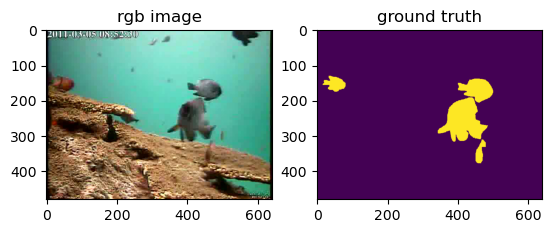

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from skimage.io import imread
import os

vid_path = 'Video/'
gt_path = 'GroundTruth/'

seq0 = [685,705]
seq1 = [1173,1191]

for no in range(*seq1):
    fid = os.path.join(vid_path,'frame%04d.jpg'%no)
    rgb = imread(fid)    
    
    fid =  os.path.join(gt_path,'%d.png'%no)
    supervision = imread(fid)
    
    plt.figure()
    plt.subplot(1,2,1)
    plt.title('rgb image')
    plt.imshow(rgb)
    plt.subplot(1,2,2)
    plt.imshow(supervision)
    plt.title('ground truth')
    break #stop after one frame for test purpose

In [2]:
# usually when you want to obtain some object like in this video, we need to substract a scene called BACKGROUND_DETECTION - BACKGROUND = OBJECT_DETECTED


## Background image (Video segmentation)

When analyzing video sequences, we can use the *movement of the frame* to help our object segmentation. In this video, our goal is to segment the fish from the background. The background here is the part of the image that doesn't change from frame to frame: detecting the objects can therefore be done using **background subtraction**.

Implement the background subtraction algorithm:

1. Initialize background image: $B_{0} = I_{0}$ where $I_t$ is the image at time $t$ and $B$ is the estimated background. 
1. Update background: $B_{t} = \alpha B_{t-1} + (1-\alpha) I_t$
> What is the purpose of $\alpha$? How can you determine that your background estimation is "stable" and can be used?
1. Subtract background to detect foreground: $F_t = I_t - B_t$
1. Find a good post-processing to clean-up the foreground image. Label the individual objects (fish).
1. Using the supervised part of the sequence, estimate the detection error of your algorithm.
> *Hint: useful metrics for segmentation performance include per-pixel accuracy, precision, recall, or F1-score (DICE). These measures can also be made per-object, which is slightly more difficult to compute but in many applications a better indicator of the actual performance of the algorithm.*

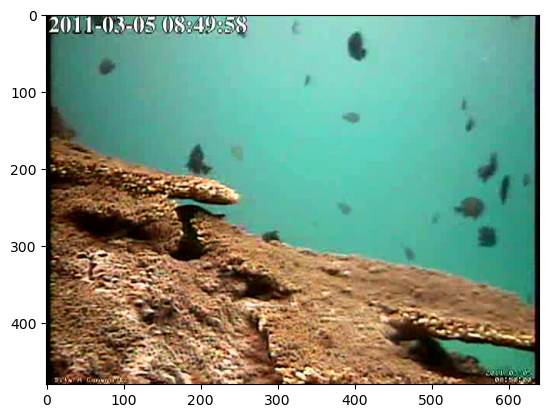

In [ ]:
B = imread(os.path.join(vid_path, 'frame%04d.jpg'%1 ))
plt.figure()
plt.imshow(B)
plt.show()

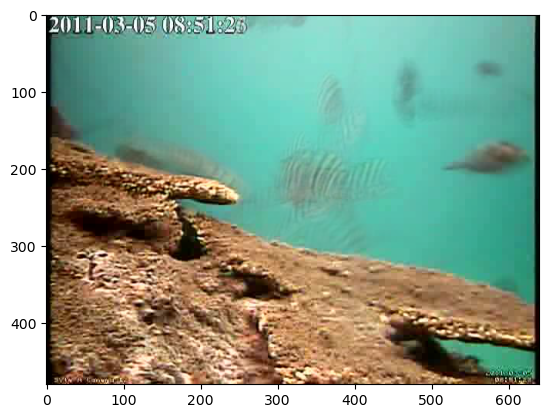

In [4]:
alpha = 0.9
for f in range(2, seq0[0]):
    I = imread(os.path.join(vid_path, 'frame%04d.jpg'%f )) # read the correct image
    B = alpha * B + (1-alpha) * I

plt.figure()
plt.imshow(B/255)
plt.show()

9.505302833211783e-06 311.1072863384359


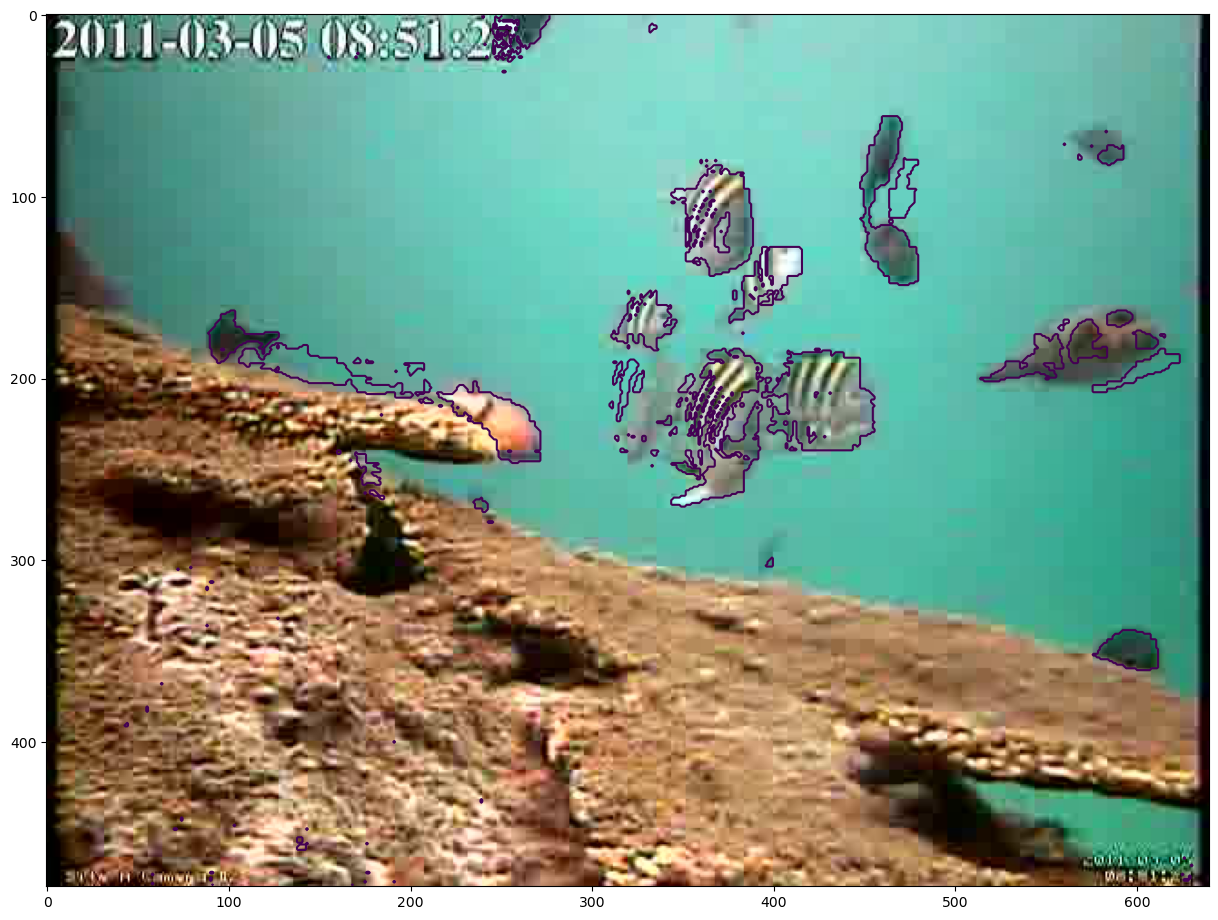

In [5]:
F = np.sqrt(((I - B)**2).sum(axis =2))
print(F.min(), F.max())
fg_mask = F > 50
plt.figure(figsize=(15,15)) 
plt.imshow(I)
plt.contour(fg_mask)
plt.show()

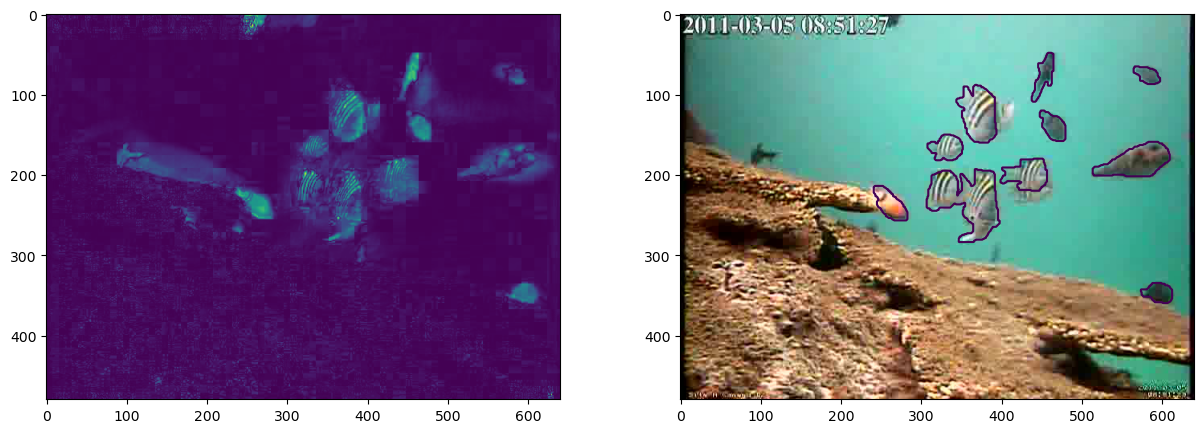

In [6]:
# Now we need to define some post processing operations to clean the segmentation

# in particular we want to estimate the detection error

for f in range(*seq0):
    I = imread(os.path.join(vid_path, 'frame%04d.jpg'%f ))
    F = np.sqrt(((I-B)**2).sum(axis=2))
    S = imread(os.path.join(gt_path, '%d.png'%f )) > 0
    plt.figure(figsize=(15,5))
    plt.subplot(1,2,1)
    plt.imshow(F)
    plt.subplot(1,2,2)
    plt.imshow(I)
    plt.contour(S)
    plt.show()
    break

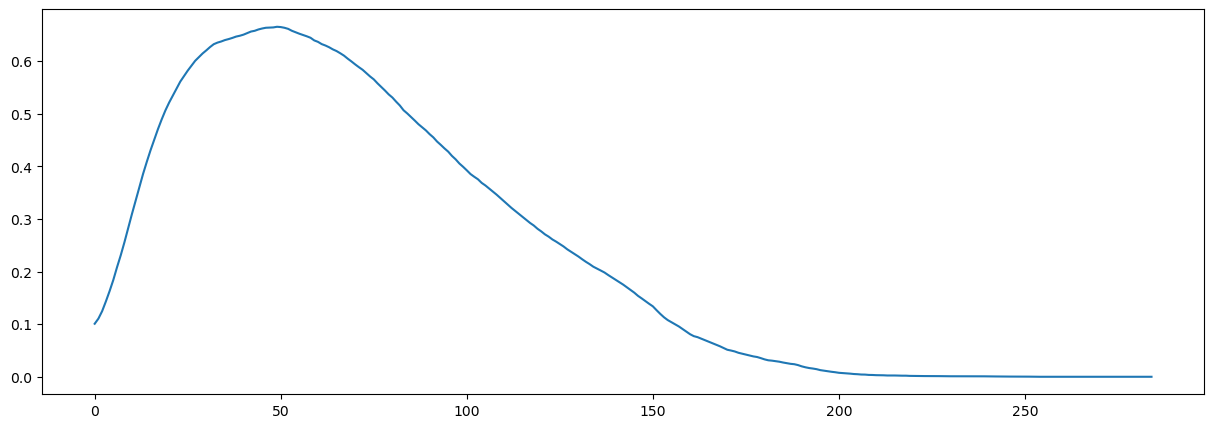

1.0


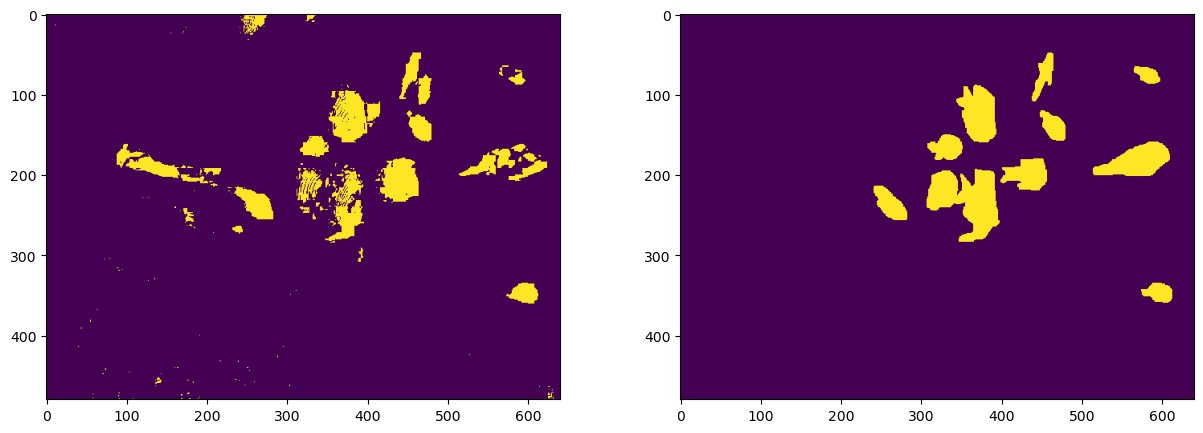

In [7]:
def F1(gt, pred):
    intersection = ((gt == 1) * (pred==1)).sum()
    return 2*intersection/(gt.sum()+pred.sum())
                           
f1_score = []
for t in range(int(F.max())):
    f1_score.append(F1(S, F > t))


# the first plot showed (for vary t) the threshold trend, to get a good prediction we need to use the function
# np.argmax that are going to get the maximum value achived of this t 

plt.figure(figsize=(15,5))
plt.plot(f1_score)
plt.show()

t = np.argmax(f1_score)
P = F > t


print(F1(S, S))



# left plot = supervision plot, right plot = prediction plot

# to remove some noise of supervision plot, we should use morphological operation

plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.imshow(P)
plt.subplot(1,2,2)
plt.imshow(S)
plt.show()


# dsc mean: overlap between two segmentations, so the number of pixels into (prediction_mask, supervision_mask)



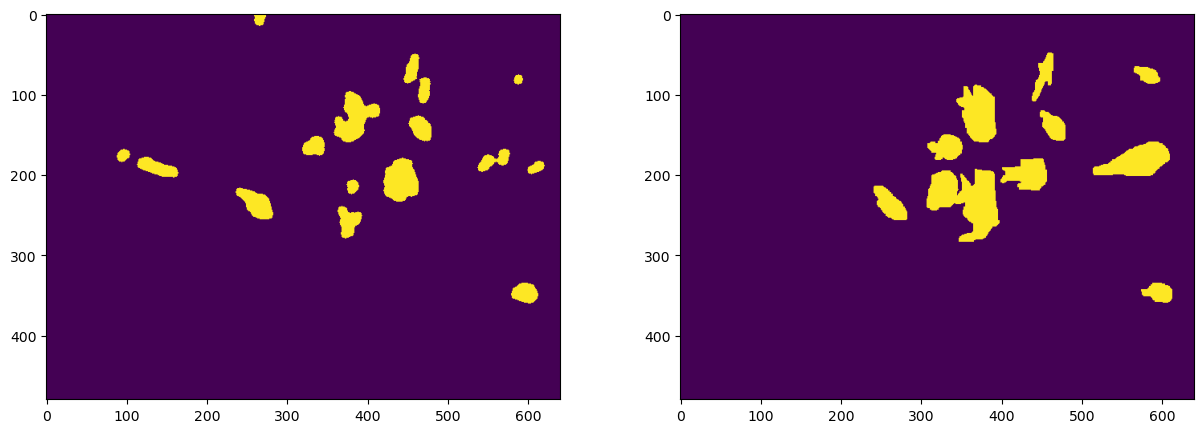

In [8]:
from skimage.morphology import opening, closing, disk

P2 = opening(P, disk(5))
P2 = closing(P2, disk(3))


# we lose a lot of precision at the borders because morphological operation usually smooth it



plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.imshow(P2)
plt.subplot(1,2,2)
plt.imshow(S)
plt.show()

## Object tracking

1. Extract interesting features from the detected objects.
1. Suggest a method to recognise and track objects from one frame to the next frame.

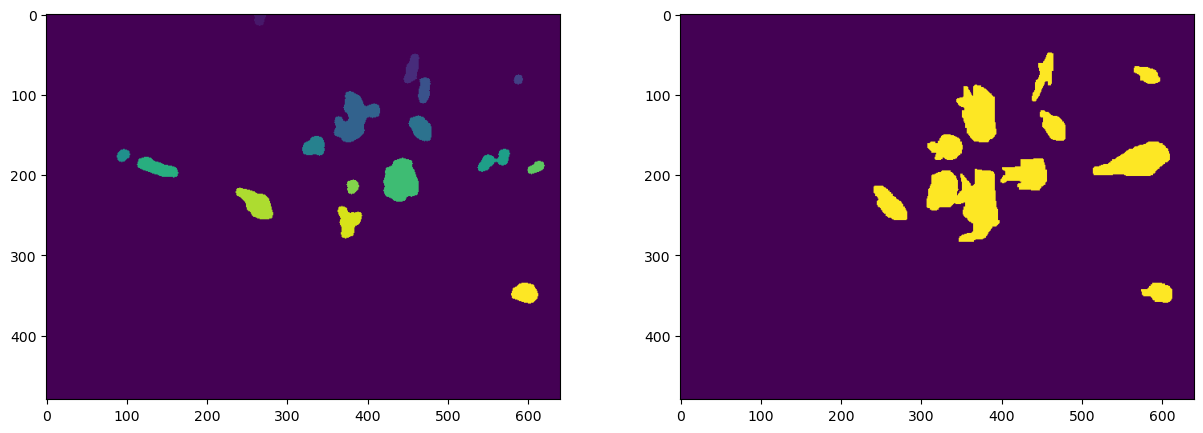

In [9]:
from skimage.measure import label

label = label(P2)
plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.imshow(label)
plt.subplot(1,2,2)
plt.imshow(S)
plt.show()

# we have exaclty for a groups of pixel the same label, this is the reason why we have different color for different shape of object



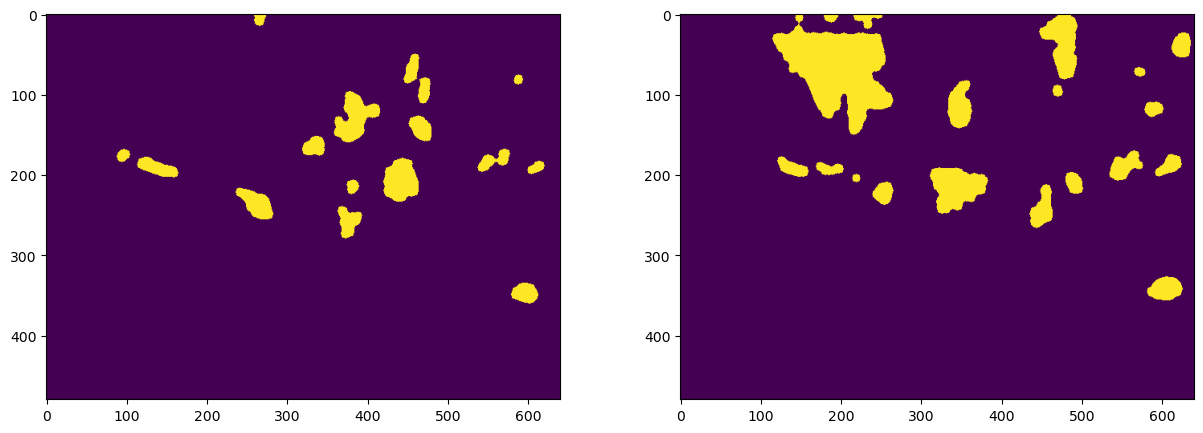

In [11]:
from skimage.measure import label
start_frame = seq0[0]+15

I = imread(os.path.join(vid_path, 'frame%04d.jpg'%(start_frame) ))
F = np.sqrt(((I-B)**2).sum(axis=2))
S = imread(os.path.join(gt_path, '%d.png'%(start_frame) )) > 0

P = opening(F > t, disk(5))
P = closing(P, disk(3))
labels = label(P)

f = start_frame

I_next = imread(os.path.join(vid_path, 'frame%04d.jpg'%(f+1) ))
F_next = np.sqrt(((I_next-B)**2).sum(axis=2))
S_next = imread(os.path.join(gt_path, '%d.png'%(f+1) )) > 0

P_next2 = F_next > t

P_next = opening(P_next2, disk(5))
P_next = closing(P_next, disk(3))
labels_next = label(P_next)



plt.figure(figsize=(15,5))
plt.subplot(1,2,1)
plt.imshow(P2)
#plt.contour(P2)
plt.subplot(1,2,2)
#plt.imshow(I_next)
plt.imshow(P_next)
#plt.contour(P_next)
plt.show()


# the algorithm is going to merge two musk that are connected each other
# so for some shape that are relatively close (close musks with different shape) are merged into one obj




1 [2]


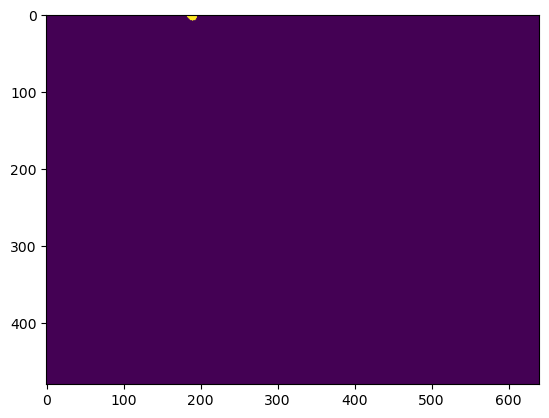

2 [0 1 3]


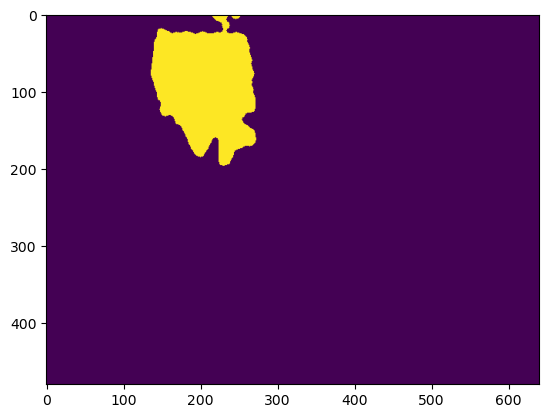

3 [0]


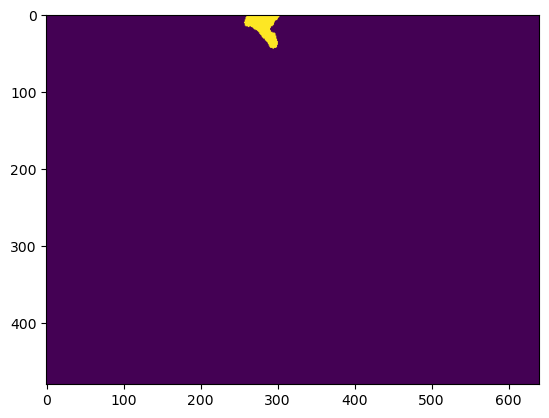

4 [0 4]


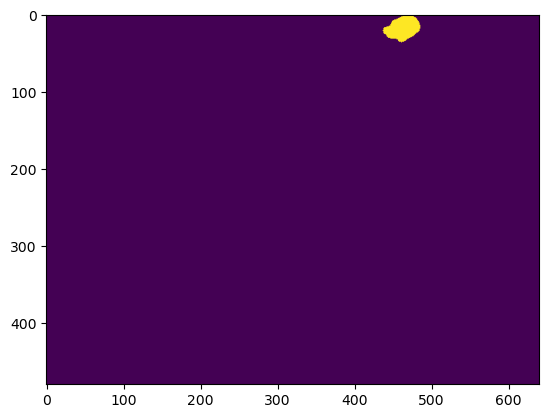

5 [0 4 8]


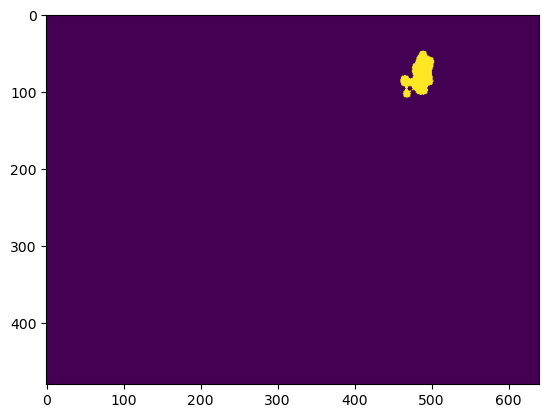

6 [0 6]


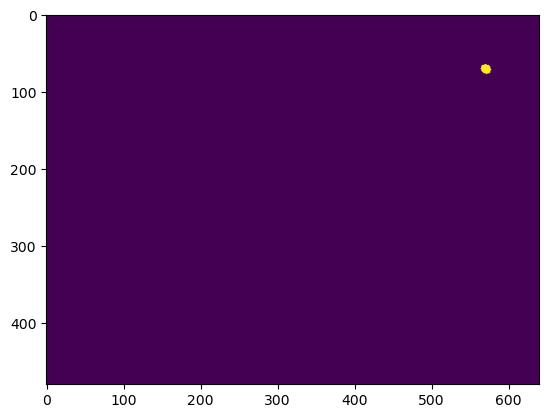

7 [0 7]


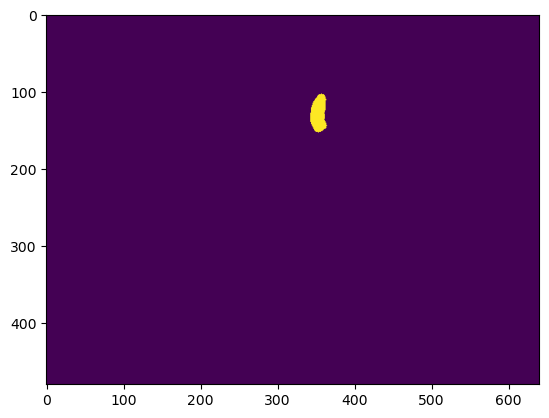

8 [0 9]


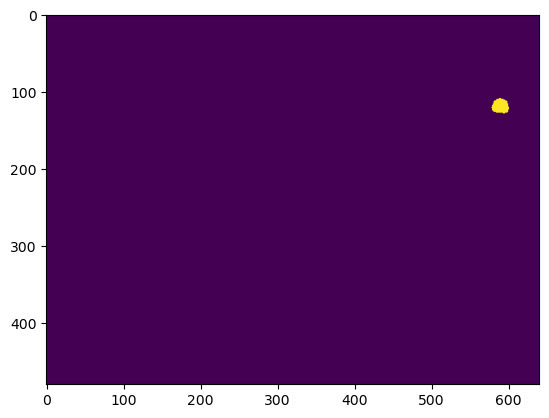

9 [ 0 10]


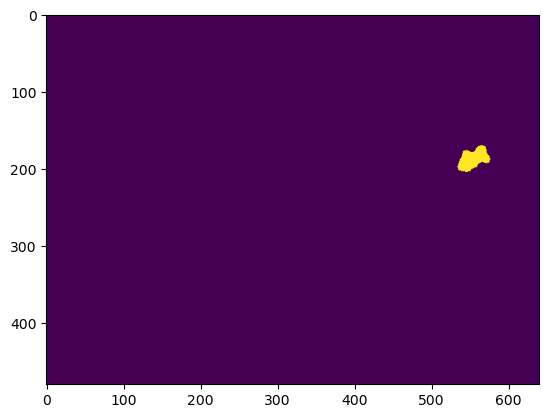

10 [ 0 11]


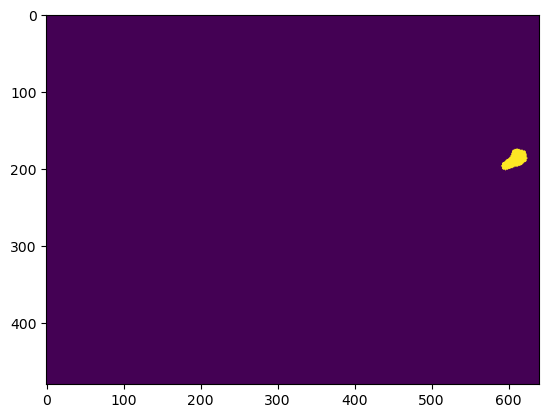

11 [ 0 12]


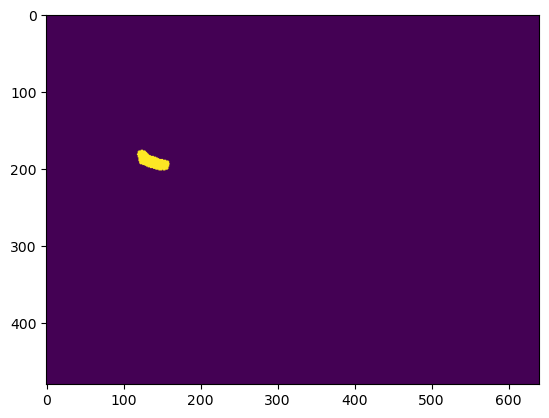

12 [ 0 15]


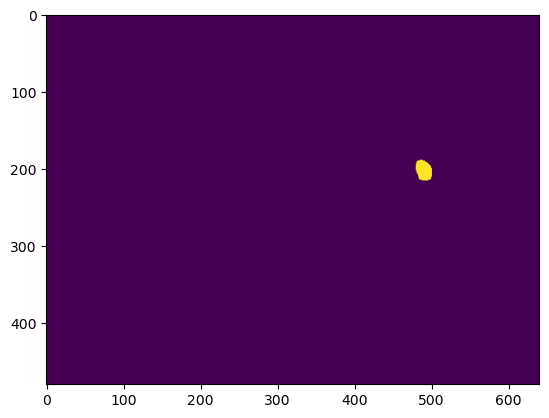

13 [ 0 14]


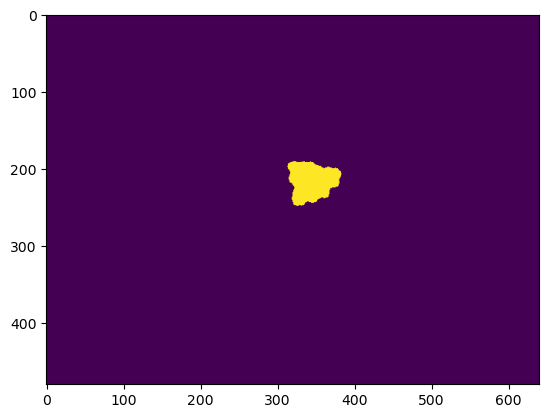

14 [17]


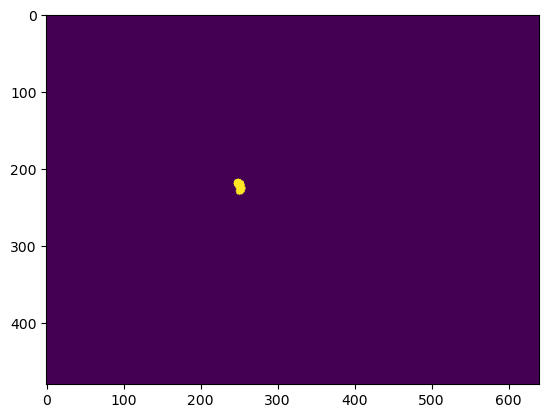

15 [ 0 18]


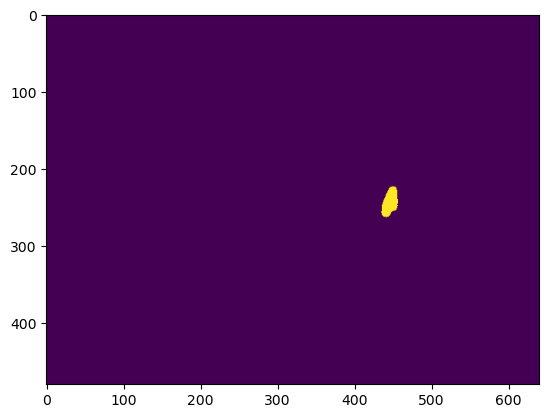

16 [ 0 19]


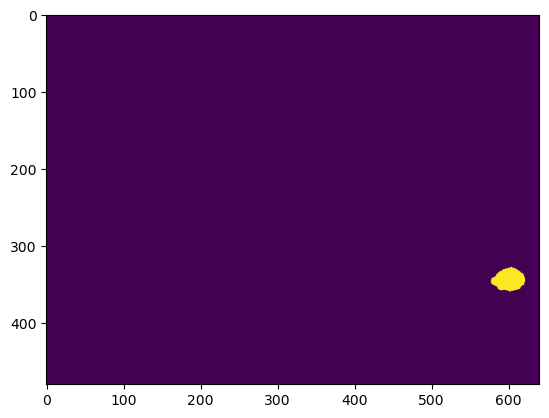

In [ ]:
for lab in range(1, labels.max()+1):
    matching_objects = np.unique(labels_next[labels==lab])
    print(lab, matching_objects)

    plt.figure()
    plt.imshow(labels==lab)
    plt.show()


# for the first one we have two match

# for the second one: we can say the object overlap part of the background of the next frame and match two distinct object in the next frame   



